In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv('../data/raw/SWAT_Dataset.csv') 

print(df.shape)
print(df.dtypes)

df.head(3)

(1000, 53)
P206             float64
DPIT301          float64
FIT301           float64
LIT301           float64
MV301            float64
MV302            float64
MV303            float64
MV304            float64
P301             float64
P302             float64
AIT401           float64
AIT402           float64
FIT401           float64
LIT401           float64
P401             float64
P402             float64
P403             float64
P404             float64
UV401            float64
AIT501           float64
AIT502           float64
AIT503           float64
AIT504           float64
FIT501           float64
FIT502           float64
FIT503           float64
FIT504           float64
P501             float64
P502             float64
PIT501           float64
PIT502           float64
PIT503           float64
FIT601           float64
P601             float64
P602             float64
P603             float64
Sensor_0         float64
Sensor_1         float64
Sensor_2         float64
Sensor_3      

,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,...,Sensor_7,Sensor_8,Sensor_9,Sensor_10,Sensor_11,Sensor_12,Sensor_13,Sensor_14,Sensor_15,Normal/Attack
0,-0.055594,0.086798,-0.007746,0.009521,0.010871,-0.105237,0.039536,-0.001122,0.022959,0.017088,...,-0.046618,0.001077,0.064121,0.036526,0.069019,0.013635,0.059512,-0.004906,0.067450,Normal
1,0.034959,0.031064,0.057486,0.039426,0.002621,0.122682,0.035406,0.016664,0.001450,-0.044175,...,0.020100,0.021540,0.116466,-0.027163,0.004958,0.031980,-0.076626,-0.067625,0.012502,Normal
2,0.051973,0.009757,0.030969,0.008433,0.051923,0.048904,0.085498,0.068519,0.014229,-0.084568,...,0.080807,0.007196,0.054676,0.089395,-0.023598,0.022599,0.125092,0.011271,0.037349,Normal


In [5]:
print(df['Normal/Attack'].value_counts())
print(df['Normal/Attack'].value_counts(normalize=True) * 100)

Normal/Attack
Normal    850
Attack    150
Name: count, dtype: int64
Normal/Attack
Normal    85.0
Attack    15.0
Name: proportion, dtype: float64


In [6]:
missing = df.isnull().sum()

missing[missing > 0]

Series([], dtype: int64)

In [7]:
features = df.drop(columns=['Normal/Attack'])
features.describe().T

,count,mean,std,min,25%,50%,75%,max
P206,1000.0,0.015824,0.820465,-5.292342,-0.650460,0.077070,0.689530,4.629824
DPIT301,1000.0,0.033283,0.834266,-5.634425,-0.718263,0.095052,0.757510,5.350051
FIT301,1000.0,0.027731,0.919444,-5.793196,-0.759419,0.068178,0.811322,5.812828
LIT301,1000.0,0.029893,0.697126,-5.471593,-0.570456,0.076269,0.611740,5.160416
MV301,1000.0,0.033121,0.831784,-5.594528,-0.643091,0.073074,0.694387,5.174511
MV302,1000.0,0.033938,0.854613,-5.721735,-0.705137,0.081283,0.748054,5.441712
MV303,1000.0,0.018809,0.830989,-5.377872,-0.690069,0.077837,0.711004,5.219382
MV304,1000.0,0.034900,0.813305,-5.600654,-0.663187,0.078635,0.701541,5.127820
P301,1000.0,0.031621,0.716930,-5.296154,-0.534615,0.068701,0.579327,5.251573
P302,1000.0,0.046750,0.835172,-5.447016,-0.692280,0.094494,0.759812,5.337267


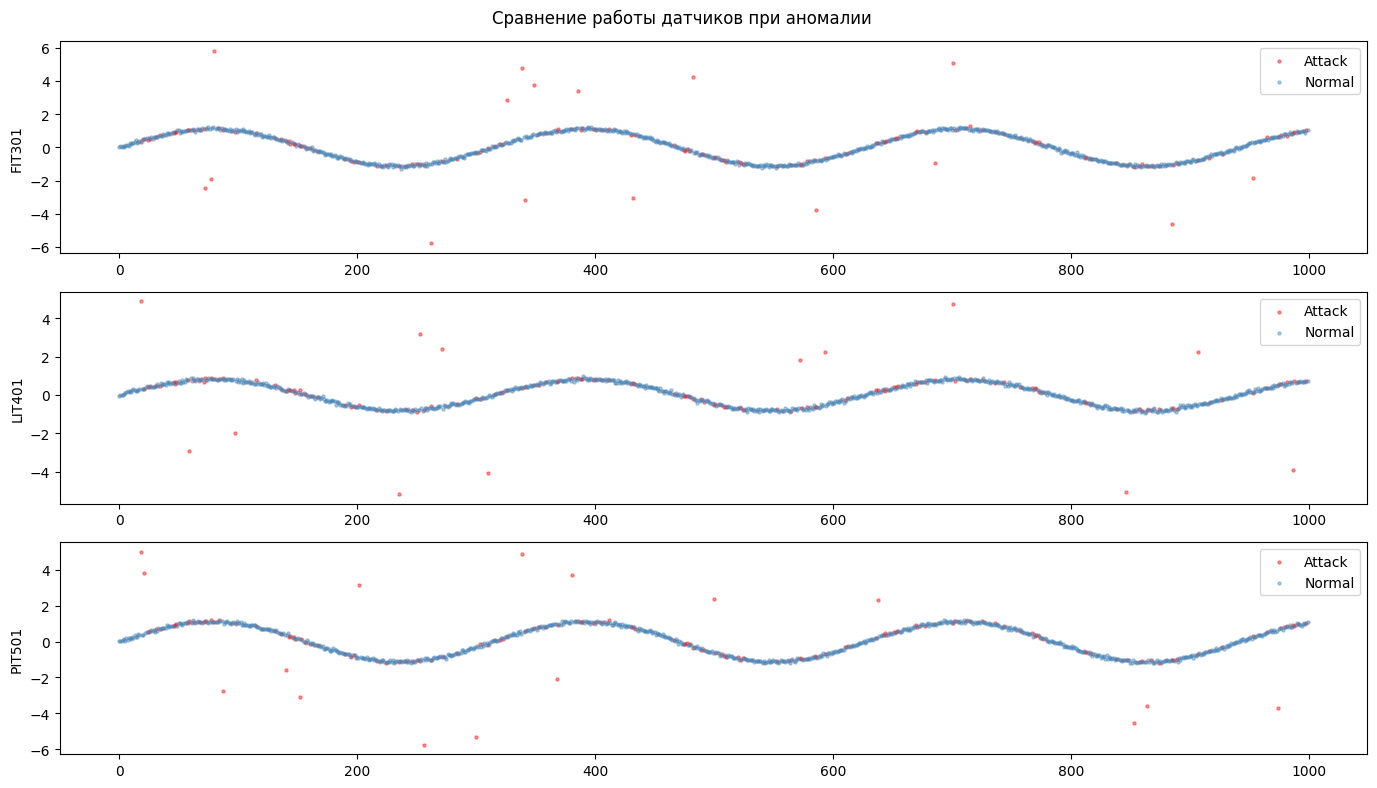

In [8]:
fig, axes = plt.subplots(3, 1, figsize=(14, 8))

sensors = ['FIT301', 'LIT401', 'PIT501']
colors = {'Normal': 'steelblue', 'Attack': 'red'}

for ax, sensor in zip(axes, sensors):
    for label, group in df.groupby('Normal/Attack'):
        ax.scatter(group.index, group[sensor],
                   c=colors[label], label=label,
                   alpha=0.4, s=5)
    ax.set_ylabel(sensor)
    ax.legend()

plt.suptitle('Сравнение работы датчиков при аномалии')
plt.tight_layout()
plt.savefig('../data/processed/eda_sensors.png', dpi=150)
plt.show()


In [9]:
df.groupby('Normal/Attack').mean()

,P206,DPIT301,FIT301,LIT301,MV301,MV302,MV303,MV304,P301,P302,...,Sensor_6,Sensor_7,Sensor_8,Sensor_9,Sensor_10,Sensor_11,Sensor_12,Sensor_13,Sensor_14,Sensor_15
Normal/Attack,,,,,,,,,,,,,,,,,,,,,
Attack,-0.004082,0.095057,0.067624,0.108566,0.121826,0.127440,0.035794,0.119263,0.120385,0.202314,...,0.114004,0.125653,0.017618,0.057488,-0.064557,0.166202,0.091299,0.040274,0.036991,0.055262
Normal,0.019337,0.022382,0.020691,0.016009,0.017467,0.017437,0.015812,0.020012,0.015957,0.019298,...,0.020638,0.017877,0.016184,0.017648,0.020284,0.021549,0.021897,0.019759,0.023191,0.018002


1. Shape: (1000, 53) - 52 признака и 1 таргет. 
2. Пропущенных значений нет.
3. Class balance: Normal=850 (85%), Attack=150 (15%).
4. Среднее у всех признаков примерно 0, стандартное отклонение от $0.6$ до $0.9$ где-то. Будем использовать StandardScaler.
5. Аномалии отклоняются от обычного паттерна, поэтому PCA должен сработать как будто.

In [10]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

features = df.drop(columns=['Normal/Attack'])
X_normal = features[df['Normal/Attack'] == 'Normal'].values

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_normal)

pca_full = PCA().fit(X_scaled)
cumvar = np.cumsum(pca_full.explained_variance_ratio_)

In [11]:
print("Компонента | % дисперсии | Накопленный %")
print("-" * 45)
for i, (ratio, cumul) in enumerate(
    zip(pca_full.explained_variance_ratio_[:5], cumvar[:5]), 1
):
    print(f"    PC{i:<3}   |   {ratio*100:5.2f}%     |    {cumul*100:.2f}%")


Компонента | % дисперсии | Накопленный %
---------------------------------------------
    PC1     |   99.48%     |    99.48%
    PC2     |    0.02%     |    99.50%
    PC3     |    0.02%     |    99.52%
    PC4     |    0.02%     |    99.54%
    PC5     |    0.02%     |    99.55%


Тогда выберем только 1 или 2 главные компоненты. Они уже объясняют более $99.5\%$ дисперсии. Видимо, данные всех 52 датчиков генерировались как синус и какой-то случайный шум..

Поэтому идея с PCA сработает идеально, тк если точка нормальная, то она лежит близко к этой самой синусоиде $\implies$ PC1 ее хорошо реконструирует $\implies$ ошибка маленькая

In [ ]:
import sys
sys.path.append('..')
from src.anomaly_detector import AnomalyDetector

features = df.drop(columns=['Normal/Attack'])
X_normal = features[df['Normal/Attack'] == 'Normal'].values
X_attack  = features[df['Normal/Attack'] == 'Attack'].values

detector = AnomalyDetector(n_components=1)
detector.fit(X_normal)

score_normal = detector.anomaly_score(X_normal)
score_attack  = detector.anomaly_score(X_attack)

print(f"Средняя ошибка на нормальных данных {score_normal.mean():.4f}")
print(f"Средняя ошибка на аномальных данных {score_attack.mean():.4f}")

Средняя ошибка на нормальных данных 0.0052
Средняя ошибка на аномальных данных 2.3795


Выглядит изумительно! PCA идеально реконструирует нормальное поведение.

In [ ]:
pred_normal = detector.predict(X_normal)
pred_attack = detector.predict(X_attack)

print(f"Ложных тревог на норм данных: {pred_normal.sum()} из {len(pred_normal)}")
print(f"Найдено аномалий: {pred_attack.sum()} из {len(pred_attack)}")

Ложных тревог на норм данных: 8 из 850
Найдено аномалий: 150 из 150


Красота! Можем это же увидеть и на графике

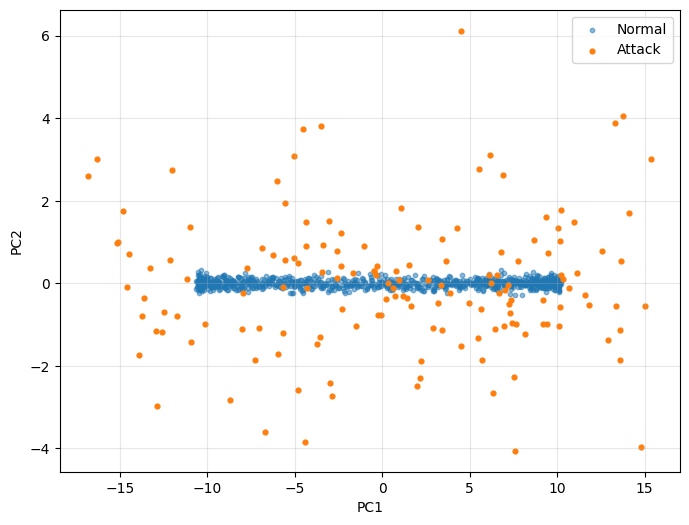

In [28]:
from src.pca_numpy import PCAnumpy

features = df.drop(columns=['Normal/Attack'])
labels = df['Normal/Attack'].values

X_normal = features[labels == 'Normal'].values
X_all = features.values

scaler = StandardScaler()
X_normal_sc = scaler.fit_transform(X_normal) # type: ignore
X_all_sc = scaler.transform(X_all)

pca = PCAnumpy(n_components=2)
pca.fit(X_normal_sc)

X_2d = pca.transform(X_all_sc)

is_normal = labels == 'Normal'
is_attack = labels == 'Attack'

plt.figure(figsize=(8, 6))
plt.scatter(X_2d[is_normal, 0], X_2d[is_normal, 1], s=10, alpha=0.5, label='Normal')
plt.scatter(X_2d[is_attack, 0], X_2d[is_attack, 1], s=12, label='Attack')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig('../data/processed/pca_visualization.png', dpi=150)
plt.show()